In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


Libraries imported successfully!
Pandas: 2.2.3
NumPy: 2.4.6


In [2]:

uploaded = files.upload()

file_name = next(iter(uploaded))

print("Uploaded file:", file_name)


Saving task1_marketplace_delivery_sla_raw.csv to task1_marketplace_delivery_sla_raw.csv
Uploaded file: task1_marketplace_delivery_sla_raw.csv


In [3]:

df = pd.read_csv(file_name)

df_original = df.copy()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (10, 13)


,order_id,customer_id,order_date,shipped_at,delivered_at,updated_at,city,courier,payment_status,order_status,promised_days,order_value,is_test_order
0,O1001,C01,29-04-26,01-05-26,03-05-26,03-05-26,Bengaluru,ShipQuick,Paid,Delivered,2,1200,No
1,O1002,C02,02-05-26,03-05-26,07-05-26,07-05-26,Mumbai,shipquick,pending,delivered,3,900,No
2,O1002,C02,02-05-26,03-05-26,07-05-26,08-05-26,Mumbai,ShipQuick,Paid,Delivered,3,900,No
3,O1003,C03,04-05-26,05-05-26,06-05-26,06-05-26,Delhi,FastBee,Pending,Delivered,2,650,No
4,O1004,C04,05-05-26,06-05-26,01-06-26,01-06-26,Pune,Blue Dart,Paid,Delivered,4,2000,No


In [4]:

print("Dataset dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 records:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset dimensions:
Rows: 10
Columns: 13

Column names:
['order_id', 'customer_id', 'order_date', 'shipped_at', 'delivered_at', 'updated_at', 'city', 'courier', 'payment_status', 'order_status', 'promised_days', 'order_value', 'is_test_order']

Data types:
order_id          object
customer_id       object
order_date        object
shipped_at        object
delivered_at      object
updated_at        object
city              object
courier           object
payment_status    object
order_status      object
promised_days      int64
order_value        int64
is_test_order     object
dtype: object

First 5 records:


,order_id,customer_id,order_date,shipped_at,delivered_at,updated_at,city,courier,payment_status,order_status,promised_days,order_value,is_test_order
0,O1001,C01,29-04-26,01-05-26,03-05-26,03-05-26,Bengaluru,ShipQuick,Paid,Delivered,2,1200,No
1,O1002,C02,02-05-26,03-05-26,07-05-26,07-05-26,Mumbai,shipquick,pending,delivered,3,900,No
2,O1002,C02,02-05-26,03-05-26,07-05-26,08-05-26,Mumbai,ShipQuick,Paid,Delivered,3,900,No
3,O1003,C03,04-05-26,05-05-26,06-05-26,06-05-26,Delhi,FastBee,Pending,Delivered,2,650,No
4,O1004,C04,05-05-26,06-05-26,01-06-26,01-06-26,Pune,Blue Dart,Paid,Delivered,4,2000,No



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   order_id        10 non-null     object
 1   customer_id     10 non-null     object
 2   order_date      10 non-null     object
 3   shipped_at      10 non-null     object
 4   delivered_at    9 non-null      object
 5   updated_at      10 non-null     object
 6   city            10 non-null     object
 7   courier         10 non-null     object
 8   payment_status  10 non-null     object
 9   order_status    10 non-null     object
 10  promised_days   10 non-null     int64 
 11  order_value     10 non-null     int64 
 12  is_test_order   10 non-null     object
dtypes: int64(2), object(11)
memory usage: 1.1+ KB


In [5]:

print("Missing values:")
display(df.isnull().sum().to_frame("missing_count"))

print("\nExact duplicate rows:")
print(df.duplicated().sum())

display(df[df.duplicated(keep=False)])

print("\nDuplicate order IDs:")
display(
    df[df.duplicated(subset="order_id", keep=False)]
    .sort_values(["order_id", "updated_at"])
)

print("\nUnique couriers:")
print(df["courier"].unique())

print("\nOrder statuses:")
print(df["order_status"].value_counts(dropna=False))

print("\nPayment statuses:")
print(df["payment_status"].value_counts(dropna=False))

print("\nTest order values:")
print(df["is_test_order"].value_counts(dropna=False))

print("\nPromised days:")
print(df["promised_days"].describe())


Missing values:


,missing_count
order_id,0
customer_id,0
order_date,0
shipped_at,0
delivered_at,1
updated_at,0
city,0
courier,0
payment_status,0
order_status,0



Exact duplicate rows:
1


,order_id,customer_id,order_date,shipped_at,delivered_at,updated_at,city,courier,payment_status,order_status,promised_days,order_value,is_test_order
6,O1006,C06,10-05-26,11-05-26,14-05-26,14-05-26,Mumbai,Bluedart,Paid,Delivered,3,1500,No
7,O1006,C06,10-05-26,11-05-26,14-05-26,14-05-26,Mumbai,Bluedart,Paid,Delivered,3,1500,No



Duplicate order IDs:


,order_id,customer_id,order_date,shipped_at,delivered_at,updated_at,city,courier,payment_status,order_status,promised_days,order_value,is_test_order
1,O1002,C02,02-05-26,03-05-26,07-05-26,07-05-26,Mumbai,shipquick,pending,delivered,3,900,No
2,O1002,C02,02-05-26,03-05-26,07-05-26,08-05-26,Mumbai,ShipQuick,Paid,Delivered,3,900,No
6,O1006,C06,10-05-26,11-05-26,14-05-26,14-05-26,Mumbai,Bluedart,Paid,Delivered,3,1500,No
7,O1006,C06,10-05-26,11-05-26,14-05-26,14-05-26,Mumbai,Bluedart,Paid,Delivered,3,1500,No



Unique couriers:
['ShipQuick' 'shipquick' 'FastBee' 'Blue Dart' 'Fastbee' 'Bluedart']

Order statuses:
order_status
Delivered    8
delivered    1
Cancelled    1
Name: count, dtype: int64

Payment statuses:
payment_status
Paid       8
pending    1
Pending    1
Name: count, dtype: int64

Test order values:
is_test_order
No     9
Yes    1
Name: count, dtype: int64

Promised days:
count    10.000000
mean      2.300000
std       1.636392
min      -2.000000
25%       2.000000
50%       3.000000
75%       3.000000
max       4.000000
Name: promised_days, dtype: float64


In [7]:

df_clean = df_original.copy()

date_columns = [
    "order_date",
    "shipped_at",
    "delivered_at",
    "updated_at"
]

for col in date_columns:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        format="%d-%m-%y",
        errors="coerce"
    )

courier_mapping = {
    "shipquick": "ShipQuick",
    "fastbee": "FastBee",
    "bluedart": "Blue Dart",
    "blue dart": "Blue Dart"
}

df_clean["courier"] = (
    df_clean["courier"]
    .str.strip()
    .str.lower()
    .map(courier_mapping)
)

df_clean["order_status"] = df_clean["order_status"].str.strip().str.lower()
df_clean["payment_status"] = df_clean["payment_status"].str.strip().str.lower()
df_clean["is_test_order"] = df_clean["is_test_order"].str.strip().str.lower()

print("df_clean created successfully!")
display(df_clean.head())


df_clean created successfully!


,order_id,customer_id,order_date,shipped_at,delivered_at,updated_at,city,courier,payment_status,order_status,promised_days,order_value,is_test_order
0,O1001,C01,2026-04-29,2026-05-01,2026-05-03,2026-05-03,Bengaluru,ShipQuick,paid,delivered,2,1200,no
1,O1002,C02,2026-05-02,2026-05-03,2026-05-07,2026-05-07,Mumbai,ShipQuick,pending,delivered,3,900,no
2,O1002,C02,2026-05-02,2026-05-03,2026-05-07,2026-05-08,Mumbai,ShipQuick,paid,delivered,3,900,no
3,O1003,C03,2026-05-04,2026-05-05,2026-05-06,2026-05-06,Delhi,FastBee,pending,delivered,2,650,no
4,O1004,C04,2026-05-05,2026-05-06,2026-06-01,2026-06-01,Pune,Blue Dart,paid,delivered,4,2000,no


In [8]:

exact_duplicates = df_clean.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

df_clean = df_clean.drop_duplicates().copy()

duplicate_orders = df_clean[
    df_clean.duplicated(subset="order_id", keep=False)
].sort_values(["order_id", "updated_at"])

display(duplicate_orders)

df_clean = (
    df_clean.sort_values("updated_at")
    .drop_duplicates(subset="order_id", keep="last")
    .reset_index(drop=True)
)

print("Final dataset shape:", df_clean.shape)
display(df_clean)


Exact duplicate rows: 1


,order_id,customer_id,order_date,shipped_at,delivered_at,updated_at,city,courier,payment_status,order_status,promised_days,order_value,is_test_order
1,O1002,C02,2026-05-02,2026-05-03,2026-05-07,2026-05-07,Mumbai,ShipQuick,pending,delivered,3,900,no
2,O1002,C02,2026-05-02,2026-05-03,2026-05-07,2026-05-08,Mumbai,ShipQuick,paid,delivered,3,900,no


Final dataset shape: (8, 13)


,order_id,customer_id,order_date,shipped_at,delivered_at,updated_at,city,courier,payment_status,order_status,promised_days,order_value,is_test_order
0,O1001,C01,2026-04-29,2026-05-01,2026-05-03,2026-05-03,Bengaluru,ShipQuick,paid,delivered,2,1200,no
1,O1003,C03,2026-05-04,2026-05-05,2026-05-06,2026-05-06,Delhi,FastBee,pending,delivered,2,650,no
2,O1002,C02,2026-05-02,2026-05-03,2026-05-07,2026-05-08,Mumbai,ShipQuick,paid,delivered,3,900,no
3,O1005,C05,2026-05-08,2026-05-09,NaT,2026-05-10,Chennai,FastBee,paid,cancelled,3,700,no
4,O1006,C06,2026-05-10,2026-05-11,2026-05-14,2026-05-14,Mumbai,Blue Dart,paid,delivered,3,1500,no
5,O1007,C07,2026-05-12,2026-05-13,2026-05-15,2026-05-15,Bangalore,ShipQuick,paid,delivered,2,1,yes
6,O1008,C08,2026-05-15,2026-05-16,2026-05-18,2026-05-18,Pune,FastBee,paid,delivered,-2,500,no
7,O1004,C04,2026-05-05,2026-05-06,2026-06-01,2026-06-01,Pune,Blue Dart,paid,delivered,4,2000,no


In [9]:

may_start = pd.Timestamp("2026-05-01")
may_end = pd.Timestamp("2026-05-31")

df_clean["is_eligible"] = (
    df_clean["delivered_at"].between(may_start, may_end)
    & (df_clean["order_status"] == "delivered")
    & (df_clean["is_test_order"] == "no")
    & df_clean["shipped_at"].notna()
    & df_clean["delivered_at"].notna()
    & (df_clean["delivered_at"] >= df_clean["shipped_at"])
    & (df_clean["promised_days"] > 0)
)

df_eligible = df_clean[df_clean["is_eligible"]].copy()

print("Total cleaned orders:", len(df_clean))
print("Eligible orders:", len(df_eligible))
print("Excluded orders:", len(df_clean) - len(df_eligible))

display(df_eligible)


Total cleaned orders: 8
Eligible orders: 4
Excluded orders: 4


,order_id,customer_id,order_date,shipped_at,delivered_at,updated_at,city,courier,payment_status,order_status,promised_days,order_value,is_test_order,is_eligible
0,O1001,C01,2026-04-29,2026-05-01,2026-05-03,2026-05-03,Bengaluru,ShipQuick,paid,delivered,2,1200,no,True
1,O1003,C03,2026-05-04,2026-05-05,2026-05-06,2026-05-06,Delhi,FastBee,pending,delivered,2,650,no,True
2,O1002,C02,2026-05-02,2026-05-03,2026-05-07,2026-05-08,Mumbai,ShipQuick,paid,delivered,3,900,no,True
4,O1006,C06,2026-05-10,2026-05-11,2026-05-14,2026-05-14,Mumbai,Blue Dart,paid,delivered,3,1500,no,True


In [10]:

df_eligible["actual_transit_days"] = (
    df_eligible["delivered_at"] - df_eligible["shipped_at"]
).dt.days

df_eligible["delivery_status"] = np.where(
    df_eligible["actual_transit_days"] <= df_eligible["promised_days"],
    "On Time",
    "Late"
)

display(
    df_eligible[
        ["order_id", "courier", "actual_transit_days",
         "promised_days", "delivery_status"]
    ]
)


,order_id,courier,actual_transit_days,promised_days,delivery_status
0,O1001,ShipQuick,2,2,On Time
1,O1003,FastBee,1,2,On Time
2,O1002,ShipQuick,4,3,Late
4,O1006,Blue Dart,3,3,On Time


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [11]:

courier_summary = (
    df_eligible.groupby("courier")
    .agg(
        eligible_orders=("order_id", "count"),
        on_time_orders=("delivery_status", lambda x: (x == "On Time").sum())
    )
    .reset_index()
)

courier_summary["on_time_rate"] = (
    courier_summary["on_time_orders"]
    / courier_summary["eligible_orders"]
)

courier_summary = courier_summary.sort_values(
    "on_time_rate",
    ascending=False
).reset_index(drop=True)

display(courier_summary)


,courier,eligible_orders,on_time_orders,on_time_rate
0,Blue Dart,1,1,1.0
1,FastBee,1,1,1.0
2,ShipQuick,2,1,0.5


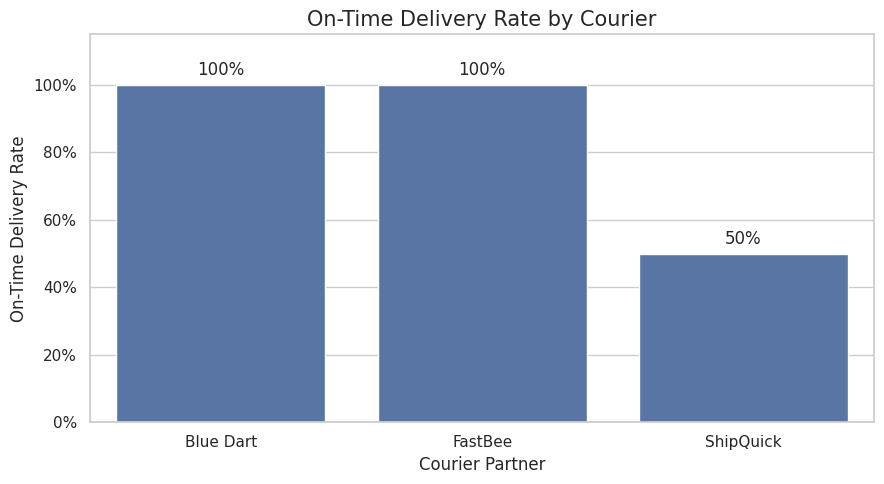

In [12]:

courier_plot = courier_summary.sort_values(
    "on_time_rate",
    ascending=False
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=courier_plot,
    x="courier",
    y="on_time_rate"
)

plt.title("On-Time Delivery Rate by Courier", fontsize=15)
plt.xlabel("Courier Partner")
plt.ylabel("On-Time Delivery Rate")

plt.ylim(0, 1.15)
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{bar.get_height():.0%}" for bar in container],
        padding=4
    )

plt.tight_layout()
plt.savefig("courier_on_time_rate.png", dpi=300)
plt.show()


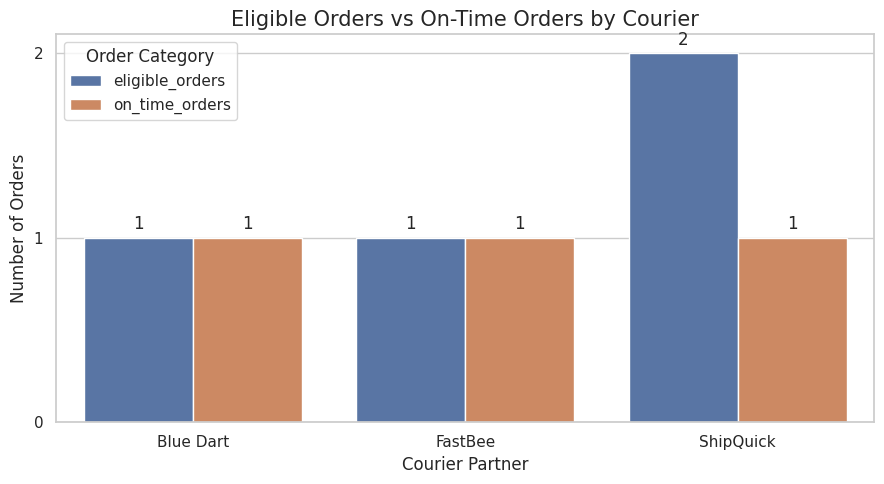

In [16]:

from matplotlib.ticker import MaxNLocator

comparison_data = courier_summary.melt(
    id_vars="courier",
    value_vars=["eligible_orders", "on_time_orders"],
    var_name="order_type",
    value_name="order_count"
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=comparison_data,
    x="courier",
    y="order_count",
    hue="order_type"
)

ax.set_title("Eligible Orders vs On-Time Orders by Courier", fontsize=15)
ax.set_xlabel("Courier Partner")
ax.set_ylabel("Number of Orders")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.legend(title="Order Category")
plt.tight_layout()
plt.savefig("courier_order_comparison.png", dpi=300)
plt.show()


In [14]:

total_eligible = len(df_eligible)

total_on_time = (
    df_eligible["delivery_status"] == "On Time"
).sum()

total_late = (
    df_eligible["delivery_status"] == "Late"
).sum()

overall_on_time_rate = (
    total_on_time / total_eligible
    if total_eligible > 0 else 0
)

best_rate = courier_summary["on_time_rate"].max()
lowest_rate = courier_summary["on_time_rate"].min()

best_couriers = courier_summary.loc[
    courier_summary["on_time_rate"] == best_rate,
    "courier"
].tolist()

lowest_couriers = courier_summary.loc[
    courier_summary["on_time_rate"] == lowest_rate,
    "courier"
].tolist()

print("MARKETPLACE DELIVERY PERFORMANCE REPORT")
print("-" * 45)

print("Total eligible orders:", total_eligible)
print("On-time orders:", total_on_time)
print("Late orders:", total_late)

print(f"Overall on-time delivery rate: {overall_on_time_rate:.2%}")

print("Highest observed rate:", ", ".join(best_couriers))
print(f"Highest rate: {best_rate:.2%}")

print("Lowest observed rate:", ", ".join(lowest_couriers))
print(f"Lowest rate: {lowest_rate:.2%}")

print("\nCOURIER PERFORMANCE")
display(courier_summary)


MARKETPLACE DELIVERY PERFORMANCE REPORT
---------------------------------------------
Total eligible orders: 4
On-time orders: 3
Late orders: 1
Overall on-time delivery rate: 75.00%
Highest observed rate: Blue Dart, FastBee
Highest rate: 100.00%
Lowest observed rate: ShipQuick
Lowest rate: 50.00%

COURIER PERFORMANCE


,courier,eligible_orders,on_time_orders,on_time_rate
0,Blue Dart,1,1,1.0
1,FastBee,1,1,1.0
2,ShipQuick,2,1,0.5


In [15]:

df_clean.to_csv("cleaned_marketplace_orders.csv", index=False)

df_eligible.to_csv("eligible_may_orders.csv", index=False)

courier_summary.to_csv("courier_delivery_summary.csv", index=False)

print("All output files generated successfully!")

print("1. cleaned_marketplace_orders.csv")
print("2. eligible_may_orders.csv")
print("3. courier_delivery_summary.csv")
print("4. courier_on_time_rate.png")
print("5. courier_order_comparison.png")


All output files generated successfully!
1. cleaned_marketplace_orders.csv
2. eligible_may_orders.csv
3. courier_delivery_summary.csv
4. courier_on_time_rate.png
5. courier_order_comparison.png


In [17]:
import shutil

shutil.make_archive(
    "JForce_Delivery_Analysis",
    "zip",
    "/content",
    base_dir=None
)

'/content/JForce_Delivery_Analysis.zip'